# Extended Data Fig. 12: speed, CA1 firing rate and theta vs behaviour performance, and d2 vs these covariates

Layout and statistics reproducing MATLAB figures,
statistics match functions in matlab.

Data: `../csv/FigS12_covariates_performance/figS12_sessions.csv` (raw and z-scored values) .

In [1]:
import os
import warnings

import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.tools.sm_exceptions import ConvergenceWarning

DATA = '../csv/FigS12_covariates_performance/figS12_sessions.csv'
FIGDIR = '../figure_output/supplementary/FigS12'
os.makedirs(FIGDIR, exist_ok=True)

FONT_DIR = 'fonts'
if os.path.exists(FONT_DIR):
    for f in os.listdir(FONT_DIR):
        if f.endswith(('.ttf', '.otf')):
            fm.fontManager.addfont(os.path.join(FONT_DIR, f))

RC = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Nimbus Sans TT', 'Nimbus Sans', 'Arial'], 'font.size': 7,
      'axes.linewidth': 1, 'xtick.major.width': 1, 'ytick.major.width': 1, 'xtick.major.size': 2.5,
      'ytick.major.size': 2.5, 'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False}
BLUE, GREY, BLACK, MUTED = '#2a78d6', '#b4b2a9', '#1f1f1d', '#8a887f'

## Data and within-animal z-scoring

In [2]:
df = pd.read_csv(DATA)
COVS = ['speed', 'FRstd', 'FRm', 'theta_all', 'theta_run']
OUTS = ['norm_path_length', 'norm_time', 'first_crossing']
D2 = 'd2_epoch2_running'
COV_LAB = {'speed': 'speed', 'FRstd': 'FR SD', 'FRm': 'FR mean', 'theta_all': 'theta (all)', 'theta_run': 'theta (run)'}
OUT_LAB = {'norm_path_length': 'norm. path length', 'norm_time': 'norm. time', 'first_crossing': 'first crossing'}

## Statistics reproducing MATLAB (`fitlm` RobustOpts, `anova(mdl,'summary')`, `corr` Spearman)

In [3]:
def _bisq(u):
    return (np.abs(u) < 1) * (1 - u ** 2) ** 2


def _madsigma(r, p):
    rs = np.sort(np.abs(r))
    return np.median(rs[max(1, p) - 1:]) / 0.6745


def robustfit_matlab(x, y, tune=4.685):
    # MATLAB robustfit/fitlm(...,'RobustOpts','on'): IRLS with leverage-adjusted residuals, MAD scale,
    # DuMouchel-O'Brien sigma shrunk toward OLS, cov = sigma^2 (X'X)^-1.
    X = np.c_[np.ones(len(x)), x]
    n, p = X.shape
    Q, R = np.linalg.qr(X)
    b = np.linalg.solve(R, Q.T @ y)
    E = X @ np.linalg.inv(R)
    h = np.minimum(.9999, (E * E).sum(1))
    adj = 1 / np.sqrt(1 - h)
    dfe = n - p
    ols_s = np.linalg.norm(y - X @ b) / np.sqrt(dfe)
    tiny = 1e-6 * np.std(y, ddof=1) or 1.0
    D, b0, it = np.sqrt(np.finfo(float).eps), np.zeros(p), 0
    while it == 0 or np.any(np.abs(b - b0) > D * np.maximum(np.abs(b), np.abs(b0))):
        it += 1
        if it > 50:
            break
        radj = (y - X @ b) * adj
        w = _bisq(radj / (max(_madsigma(radj, p), tiny) * tune))
        b0 = b.copy()
        sw = np.sqrt(w)
        Qw, Rw = np.linalg.qr(X * sw[:, None])
        b = np.linalg.solve(Rw, Qw.T @ (y * sw))
    radj = (y - X @ b) * adj
    st = max(_madsigma(radj, p), tiny) * tune
    u = radj / st
    phi = u * _bisq(u)
    dl = 1e-4
    dphi = ((u + dl) * _bisq(u + dl) - (u - dl) * _bisq(u - dl)) / (2 * dl)
    m1, m2 = dphi.mean(), np.sum((1 - h) * phi ** 2) / dfe
    rob_s = (1 + (p / n) * (1 - m1) / m1) * np.sqrt(m2) * st / m1
    sigma = max(rob_s, np.sqrt((ols_s ** 2 * p ** 2 + rob_s ** 2 * n) / (p ** 2 + n)))
    cov = np.linalg.inv(X.T @ X) * sigma ** 2
    se = np.sqrt(np.diag(cov))
    pv = 2 * stats.t.sf(np.abs(b / se), dfe)
    ssr = np.sum((X @ b - y.mean()) ** 2)          # anova 'summary': Model SS; Residual SS = sigma^2 * dfe
    R2 = ssr / (ssr + sigma ** 2 * dfe)
    p_model = stats.f.sf(ssr / sigma ** 2, 1, dfe)
    return dict(b=b, se=se, p=pv, cov=cov, dfe=dfe, R2=R2, p_model=p_model)


def _as89(n, S):
    c = [0.2274, 0.2531, 0.1745, 0.0758, 0.1033, 0.3932, 0.0879, 0.0151, 0.0072, 0.0831, 0.0131, 4.6e-4]
    b = 1 / n
    x = (6 * (S - 1) * b / (n * n - 1) - 1) * np.sqrt(1 / b - 1)
    y = x * x
    u = x * b * (c[0] + b * (c[1] + c[2] * b) + y * (-c[3] + b * (c[4] + c[5] * b)
                 - y * b * (c[6] + c[7] * b - y * (c[8] - c[9] * b + y * b * (c[10] - c[11] * y)))))
    return float(np.clip(u / np.exp(y / 2) + stats.norm.sf(x), 0, 1))


def spearman_matlab(x, y):
    rho, p_t = stats.spearmanr(x, y)
    n = len(x)
    if len(np.unique(x)) < n or len(np.unique(y)) < n:      # ties: t approximation
        return rho, p_t
    k = n * (n * n - 1) / 6                                  # no ties: AS 89 Edgeworth series
    return rho, min(1.0, 2 * min(_as89(n, (1 - rho) * k), _as89(n, (1 + rho) * k)))


def fit_lme(d):
    # y ~ x + (1 | animal) 
    best = None
    with warnings.catch_warnings():
        for w in (ConvergenceWarning, RuntimeWarning, UserWarning):
            warnings.simplefilter('ignore', w)
        for method in ['lbfgs', 'bfgs', 'powell', 'nm']:
            try:
                f = smf.mixedlm('y ~ x', d, groups=d['animal']).fit(reml=True, method=method)
            except Exception:
                continue
            if np.isfinite(f.llf) and (best is None or f.llf > best.llf + 1e-9):
                best = f
    s2, t2 = float(best.scale), float(best.cov_re.iloc[0, 0])
    M = np.zeros((2, 2))
    for _, g in d.groupby('animal'):
        X = np.c_[np.ones(len(g)), g['x'].to_numpy(float)]
        V_inv = (np.eye(len(g)) - t2 / (s2 + len(g) * t2) * np.ones((len(g), len(g)))) / s2
        M += X.T @ V_inv @ X
    se = float(np.sqrt(np.linalg.inv(M)[1, 1]))
    return float(best.params['x']), se, 2 * stats.norm.sf(abs(best.params['x'] / se))


def panel_stats(xv, yv, block):
    d = pd.DataFrame({'x': df[f'z_{xv}'], 'y': df[f'z_{yv}'], 'animal': df.animal, 'session': df.session}).dropna()
    f = robustfit_matlab(d.x.to_numpy(float), d.y.to_numpy(float))
    rho, p_rho = spearman_matlab(d.x.to_numpy(float), d.y.to_numpy(float))
    lb, lse, lp = fit_lme(d)
    row = {'block': block, 'x': xv, 'y': yv, 'n': len(d), 'robust_intercept': f['b'][0], 'robust_slope': f['b'][1],
           'robust_SE': f['se'][1], 'robust_p': f['p'][1], 'anova_R2': f['R2'], 'anova_p': f['p_model'],
           'spearman_rho': rho, 'spearman_p': p_rho, 'LME_slope': lb, 'LME_SE': lse, 'LME_p': lp}
    return d, f, row


panels, rows = {}, []
for yv in OUTS:
    for xv in COVS:
        d, f, r = panel_stats(xv, yv, 'A-O covariate vs performance')
        panels[(xv, yv)] = (d, f)
        rows.append(r)
for yv in COVS:
    d, f, r = panel_stats(D2, yv, 'P-T d2 vs covariate')
    panels[(D2, yv)] = (d, f)
    rows.append(r)
res = pd.DataFrame(rows)
res.to_csv(f'{FIGDIR}/FigS12_statistics.csv', index=False)

## Figure

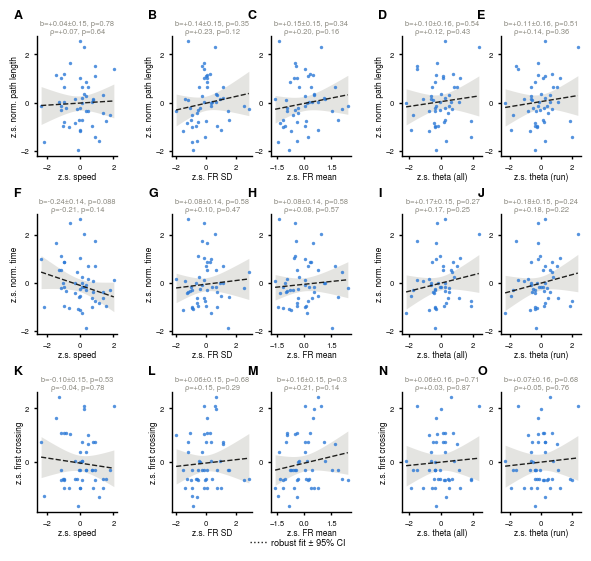

In [ ]:
def draw(ax, d, f, r, xlabel, ylabel, letter):
    ax.scatter(d.x, d.y, s=6, color=BLUE, alpha=0.8, lw=0, zorder=2)
    xs = np.linspace(d.x.min(), d.x.max(), 100)
    Xs = np.c_[np.ones_like(xs), xs]
    yh = Xs @ f['b']
    half = stats.t.ppf(0.975, f['dfe']) * np.sqrt(np.einsum('ij,jk,ik->i', Xs, f['cov'], Xs))
    ax.fill_between(xs, yh - half, yh + half, color=GREY, alpha=0.35, lw=0, zorder=1)   # plot(mdl): 95% CI of the fit
    ax.plot(xs, yh, color=BLACK, lw=1, ls='--', zorder=3)
    sig = r['robust_p'] < 0.05 or r['spearman_p'] < 0.05
    ax.set_title(f"b={r['robust_slope']:+.2f}±{r['robust_SE']:.2f}, p={r['robust_p']:.2g}\n"
                 f"ρ={r['spearman_rho']:+.2f}, p={r['spearman_p']:.2g}" + (' *' if sig else ''),
                 fontsize=5.4, pad=2, linespacing=1.15, fontweight='bold' if sig else 'normal',
                 color=BLACK if sig else MUTED)
    ax.set_xlabel(xlabel, fontsize=6, labelpad=1)
    ax.set_ylabel(ylabel, fontsize=6, labelpad=1)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(3))
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(3))
    ax.tick_params(labelsize=5.5)
    ax.text(-0.3, 1.22, letter, transform=ax.transAxes, fontsize=9, fontweight='bold', va='top')


FIG_W, AX_W, AX_H = 5.9, 0.80, 1.20
COL_X = [0.35, 1.70, 2.69, 4.00, 4.99]
ROW_Y = [0.45, 2.23, 4.01]
YLAB_COLS = {0, 1, 3}             # FRm and theta.run sit next to FRstd and theta.all, so they have no y label


def add_ax(fig, x, y, fig_h):
    return fig.add_axes([x / FIG_W, 1 - (y + AX_H) / fig_h, AX_W / FIG_W, AX_H / fig_h])


def fit_legend(fig):
    hs = [Line2D([], [], color=BLACK, lw=1, ls=':', label='robust fit ± 95% CI')]
    fig.legend(handles=hs, loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=1, frameon=False, fontsize=6.5,
               handletextpad=0.3, columnspacing=1.0)


L = iter('ABCDEFGHIJKLMNO')
with plt.rc_context(RC):
    fig_h = 5.65
    fig = plt.figure(figsize=(FIG_W, fig_h))
    for i, yv in enumerate(OUTS):
        for j, xv in enumerate(COVS):
            d, f = panels[(xv, yv)]
            r = res[(res.x == xv) & (res.y == yv)].iloc[0]
            draw(add_ax(fig, COL_X[j], ROW_Y[i], fig_h), d, f, r, f'z.s. {COV_LAB[xv]}',
                 f'z.s. {OUT_LAB[yv]}' if j in YLAB_COLS else '', next(L))
    fit_legend(fig)
    fig.savefig(f'{FIGDIR}/FigS12_covariates_performance.pdf', bbox_inches='tight')
    plt.show()

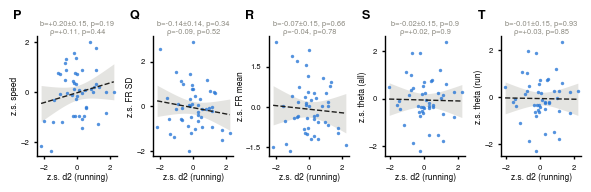

In [5]:
# d2 vs each covariate (not in the reference figure): same panel size, evenly spaced since every panel needs its own y label.
L = iter('PQRST')
with plt.rc_context(RC):
    fig_h = 1.95
    fig = plt.figure(figsize=(FIG_W, fig_h))
    for j, yv in enumerate(COVS):
        d, f = panels[(D2, yv)]
        r = res[(res.x == D2) & (res.y == yv)].iloc[0]
        draw(add_ax(fig, 0.35 + 1.16 * j, 0.45, fig_h), d, f, r, 'z.s. d2 (running)', f'z.s. {COV_LAB[yv]}', next(L))
    fig.savefig(f'{FIGDIR}/FigS12_d2_vs_covariates.pdf', bbox_inches='tight')
    plt.show()